# Task 6: Exposure-Aware PIDNet-S on NightCity (Option 1)

This notebook implements and evaluates **Option 1: Exposure-Aware Training Enhancements** for nighttime semantic segmentation:
1. **Night-Specific Augmentations:** Gamma shifts (0.4–2.2), shadow shot noise, and specular headlight/glare bloom.
2. **Exposure-Aware OHEM Loss:** Dynamically weights pixel losses according to local luminance ($W_{exp}$ upweights underexposed dark zones and overexposed glare).
3. **Auxiliary Illumination Head:** Self-supervised 3-bin lighting classification head (Dark, Normal, Glare) that guides representation learning during training and is **completely dropped at inference** (Zero FLOP / Latency overhead).


In [1]:
import os, sys, json, subprocess
from pathlib import Path

# Auto-detect Kaggle environment
IS_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ or Path("/kaggle").exists()

if IS_KAGGLE:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "yacs", "thop"])
    repo_dest = Path("/kaggle/working/AI512_Project")
    if not repo_dest.exists():
        subprocess.run(["git", "clone", "https://github.com/Gitansh-Bansal/AI512_Project.git", str(repo_dest)])
    os.chdir(str(repo_dest))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

CWD = Path(".").resolve()
REPO_ROOT = CWD if (CWD / "PIDNet").exists() else CWD.parent
PIDNET_DIR = REPO_ROOT / "PIDNet"

# Auto-locate NightCity dataset
DATA_ROOT = None
if Path("/kaggle/input").exists():
    for p in Path("/kaggle/input").rglob("NightCity-images"):
        if p.is_dir():
            DATA_ROOT = p.parent
            break
    if DATA_ROOT is None:
        for cand in [Path("/kaggle/input/datasets/gitanshb/nightcity"), Path("/kaggle/input/nightcity"), Path("/kaggle/input/nightcity-dataset")]:
            if cand.exists():
                DATA_ROOT = cand
                break

if DATA_ROOT is None:
    DATA_ROOT = (REPO_ROOT / "Data") if (REPO_ROOT / "Data").exists() else (REPO_ROOT / "AI512_Project" / "Data")

print(f"REPO_ROOT: {REPO_ROOT}")
print(f"PIDNET_DIR: {PIDNET_DIR}")
print(f"DATA_ROOT: {DATA_ROOT}")

if str(PIDNET_DIR) not in sys.path:
    sys.path.insert(0, str(PIDNET_DIR))

from models.pidnet import get_pred_model
from models.pidnet_exposure import get_exposure_model
from datasets.nightcity import NightCity
from metrics import SegmentationMetrics, CITYSCAPES_CLASSES
from benchmarks import get_hardware_info, profile_parameters, profile_flops, benchmark_inference_speed
from utils.night_augmentations import NightAugmentationPipeline
from train_exposure import run_training_exposure, plot_exposure_training_history
from eval_nightcity import colorize_mask

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device} | PyTorch: {torch.__version__}")


REPO_ROOT: C:\Users\gitan\Desktop\AI Project\AI512_Project
PIDNET_DIR: C:\Users\gitan\Desktop\AI Project\AI512_Project\PIDNet
DATA_ROOT: C:\Users\gitan\Desktop\AI Project\AI512_Project\Data


Device: cpu | PyTorch: 2.14.0+cpu


## 1. Model, Complexity & Speed (Zero Inference Overhead)


In [2]:
# Load Exposure-Aware PIDNet-S in inference mode (augment=False)
model = get_exposure_model(name="pidnet_s", num_classes=19, augment=False).to(device).eval()

with torch.no_grad():
    out = model(torch.randn(1, 3, 512, 1024, device=device))
print("Input: (1, 3, 512, 1024) -> Output:", tuple(out.shape))

param_info = profile_parameters(model)
flop_profiles = profile_flops(model, [(512, 512), (512, 1024), (1024, 2048)], device=device)
hw_info = get_hardware_info(device)
speed = benchmark_inference_speed(model, input_resolution=(512, 1024), batch_size=1, device=device, warmup_runs=10, timed_runs=25)

hw_name = hw_info.get("GPU_Device_Name", hw_info.get("CPU_Processor", "Unknown"))
if hw_name == "N/A (CPU Execution)":
    hw_name = hw_info.get("CPU_Processor", "CPU")

print(f"Params: {param_info['total_params_M']:.2f} M | Hardware: {hw_name}")
print(f"Latency (512x1024): {speed['Mean_Latency_ms']:.1f} ms | Throughput: {speed['FPS']:.2f} FPS")
display(pd.DataFrame(flop_profiles))


Input: (1, 3, 512, 1024) -> Output: (1, 19, 64, 128)


Params: 7.66 M | Hardware: Intel64 Family 6 Model 154 Stepping 4, GenuineIntel
Latency (512x1024): 145.6 ms | Throughput: 6.87 FPS


,Resolution,Height,Width,MACs_G,FLOPs_G,Params_M
0,512x512,512,512,5.966183,11.932367,7.625715
1,1024x512,512,1024,11.932315,23.864630,7.625715
2,2048x1024,1024,2048,47.729105,95.458211,7.625715


## 2. Night-Specific Augmentation Preview


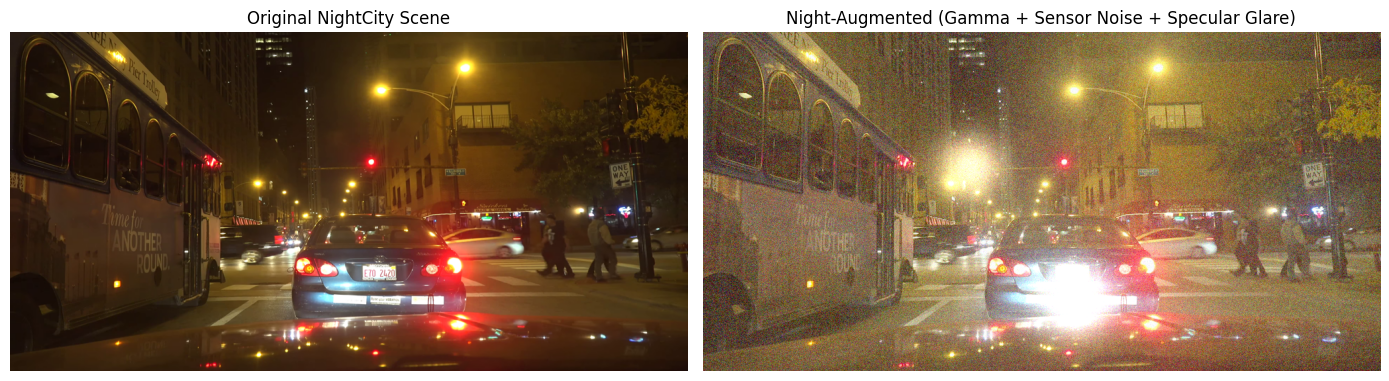

In [3]:
# Preview the synthetic night augmentations (Gamma shift, Dark sensor noise, Specular glare)
val_list_path = PIDNET_DIR / "data/list/nightcity/val.lst"
preview_ds = NightCity(root=str(DATA_ROOT), list_path=str(val_list_path), num_classes=19, multi_scale=False, flip=False)

sample_idx = min(5, len(preview_ds.files) - 1)
img_rel = preview_ds.files[sample_idx]["img"]
raw_img_path = str(DATA_ROOT / img_rel)
if not Path(raw_img_path).exists():
    raw_img_path = str(DATA_ROOT / img_rel.replace("NightCity-images/NightCity-images", "NightCity-images"))

raw_bgr = cv2.imread(raw_img_path)
if raw_bgr is not None:
    raw_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
    aug_pipeline = NightAugmentationPipeline(p=1.0)
    aug_rgb = aug_pipeline(raw_rgb.copy())

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].imshow(raw_rgb); axes[0].set_title("Original NightCity Scene"); axes[0].axis("off")
    axes[1].imshow(aug_rgb); axes[1].set_title("Night-Augmented (Gamma + Sensor Noise + Specular Glare)"); axes[1].axis("off")
    plt.tight_layout()
    plt.show()
else:
    print(f"Sample preview skipped (image not found at {raw_img_path})")


## 3. Exposure-Aware Training (NightCity)


PIDNET-S EXPOSURE-AWARE TRAINING (OPTION 1)
[INFO] Compute Device: cpu
[INFO] Epochs: 30 | Batch Size: 2 | LR: 0.001 | BD Weight: 1.0 | Illum Weight: 0.2
[INFO] Exposure Penalties: alpha_dark=1.5, beta_glare=1.2 | Night Augmentations: True
[INFO] Train Samples: 8 | Val Samples: 1,299


Epoch 1/30 [Train Exposure]:   0%|          | 0/4 [00:00<?, ?it/s]

Epoch 1/30 [Train Exposure]:   0%|          | 0/4 [00:01<?, ?it/s, loss=11.8812, sem=7.9572, bd=3.6779, illum=1.2302, lr=0.001000]

Epoch 1/30 [Train Exposure]:  25%|██▌       | 1/4 [00:01<00:03,  1.31s/it, loss=11.8812, sem=7.9572, bd=3.6779, illum=1.2302, lr=0.001000]

Epoch 1/30 [Train Exposure]:  25%|██▌       | 1/4 [00:02<00:03,  1.31s/it, loss=9.6883, sem=8.4681, bd=0.9984, illum=1.1090, lr=0.000992] 

Epoch 1/30 [Train Exposure]:  50%|█████     | 2/4 [00:02<00:02,  1.34s/it, loss=9.6883, sem=8.4681, bd=0.9984, illum=1.1090, lr=0.000992]

... (412 outputs left out)

Validating:   0%|          | 3/650 [00:02<10:19,  1.04it/s]

Validating:   1%|          | 4/650 [00:03<10:16,  1.05it/s]

  -> Validation mIoU: 10.82% | Pixel Acc: 54.99%


[INFO] Training loss plot saved to: C:\Users\gitan\Desktop\AI Project\AI512_Project\output\nightcity_pidnet_exposure\loss_vs_epoch.png


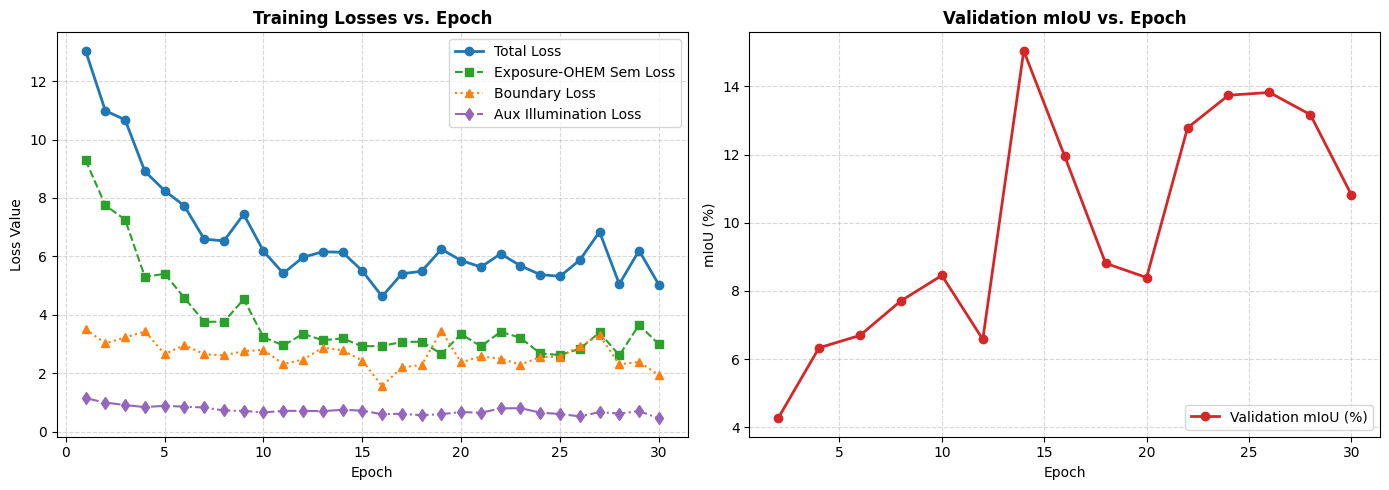

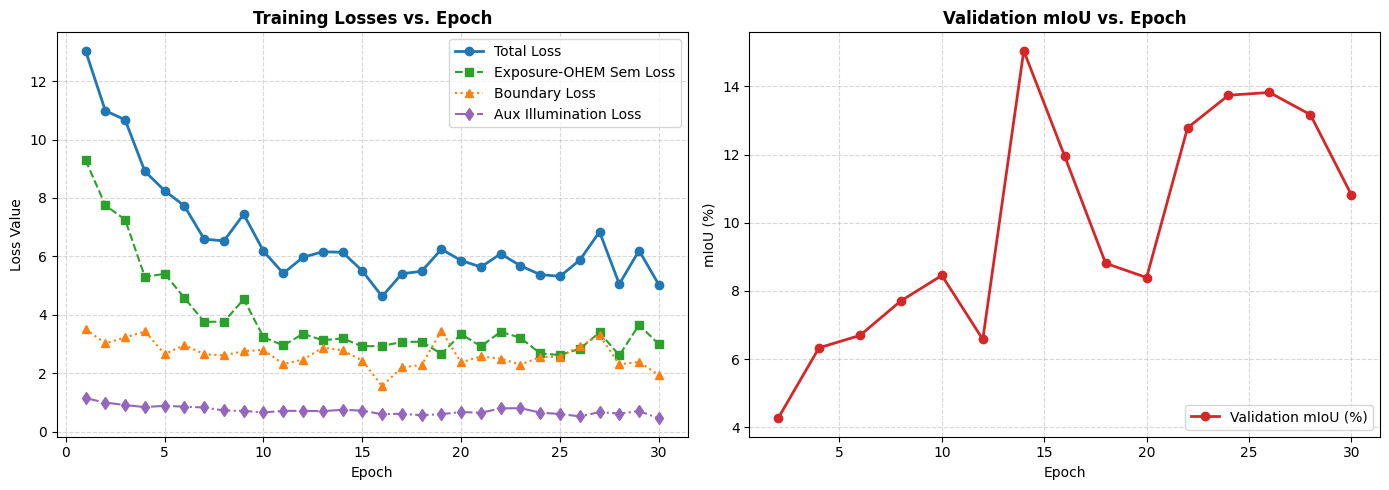

In [4]:
TRAIN_CONFIG = {
    "epochs": 30,
    "batch_size": 4 if torch.cuda.is_available() else 2,
    "optimizer": "adamw",
    "base_lr": 0.001,
    "bd_weight": 1.0,
    "illum_weight": 0.2,
    "alpha_dark": 1.5,
    "beta_glare": 1.2,
    "use_night_aug": True,
    "crop_size": (512, 512),
    "val_freq": 2,
    "val_samples": 10,
    "max_train_samples": None if torch.cuda.is_available() else 8,
    "save_dir": str(REPO_ROOT / "output" / "nightcity_pidnet_exposure"),
}

RETRAIN = True if (IS_KAGGLE and torch.cuda.is_available()) else False
history_path = Path(TRAIN_CONFIG["save_dir"]) / "training_history.json"
ckpt_path = Path(TRAIN_CONFIG["save_dir"]) / "best_pidnet_exposure.pt"

if RETRAIN or not (history_path.exists() and ckpt_path.exists()):
    history = run_training_exposure(
        data_root=str(DATA_ROOT),
        train_list=str(PIDNET_DIR / "data/list/nightcity/train.lst"),
        val_list=str(PIDNET_DIR / "data/list/nightcity/val.lst"),
        epochs=TRAIN_CONFIG["epochs"],
        batch_size=TRAIN_CONFIG["batch_size"],
        optimizer_name=TRAIN_CONFIG["optimizer"],
        base_lr=TRAIN_CONFIG["base_lr"],
        bd_weight=TRAIN_CONFIG["bd_weight"],
        illum_weight=TRAIN_CONFIG["illum_weight"],
        alpha_dark=TRAIN_CONFIG["alpha_dark"],
        beta_glare=TRAIN_CONFIG["beta_glare"],
        use_night_aug=TRAIN_CONFIG["use_night_aug"],
        crop_h=TRAIN_CONFIG["crop_size"][0],
        crop_w=TRAIN_CONFIG["crop_size"][1],
        val_freq=TRAIN_CONFIG["val_freq"],
        val_samples=TRAIN_CONFIG["val_samples"],
        num_train_samples=TRAIN_CONFIG["max_train_samples"],
        save_dir=TRAIN_CONFIG["save_dir"],
    )
else:
    history = json.loads(history_path.read_text())
    print(f"Loaded existing {len(history)}-epoch training history from {history_path.name}")

plot_exposure_training_history(history)
plt.show()


## 4. Evaluation (NightCity Validation)


In [5]:
EVAL_SAMPLES = None if torch.cuda.is_available() else 100

val_ds = NightCity(
    root=str(DATA_ROOT),
    list_path=str(PIDNET_DIR / "data/list/nightcity/val.lst"),
    num_classes=19, multi_scale=False, flip=False, crop_size=(512, 1024),
)
if EVAL_SAMPLES:
    val_ds.files = val_ds.files[:EVAL_SAMPLES]
val_loader = DataLoader(val_ds, batch_size=4 if torch.cuda.is_available() else 2, shuffle=False)

ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
state = ckpt.get("state_dict", ckpt)
model.load_state_dict({k.replace("module.", ""): v for k, v in state.items()}, strict=False)
model.eval()

metrics = SegmentationMetrics(num_classes=19, ignore_label=255, class_names=CITYSCAPES_CLASSES)
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
vis_samples = []

with torch.no_grad():
    for imgs, lbls, _, _, names in val_loader:
        preds = model(imgs.to(device))
        if isinstance(preds, list):
            preds = preds[1]
        if preds.shape[-2:] != lbls.shape[-2:]:
            preds = F.interpolate(preds, size=lbls.shape[-2:], mode="bilinear", align_corners=False)
        pred_cls = torch.argmax(preds, dim=1).cpu().numpy()
        metrics.update(pred_cls, lbls.numpy())

        for b in range(imgs.shape[0]):
            if len(vis_samples) < 3:
                rgb = np.clip((imgs[b].permute(1, 2, 0).numpy() * std + mean) * 255, 0, 255).astype(np.uint8)
                vis_samples.append((names[b], rgb, lbls[b].numpy(), pred_cls[b]))

summary = metrics.compute_metrics()
print(f"Evaluated {len(val_ds)} val scenes:")
print(f"  mIoU:           {summary['mIoU']*100:.2f}%")
print(f"  Mean Dice (F1): {summary['mean_Dice']*100:.2f}%")
print(f"  Sensitivity:    {summary['mean_Sensitivity']*100:.2f}%")
print(f"  Specificity:    {summary['mean_Specificity']*100:.2f}%")
print(f"  Pixel Accuracy: {summary['Pixel_Accuracy']*100:.2f}%")


Evaluated 100 val scenes:
  mIoU:           7.34%
  Mean Dice (F1): 10.74%
  Sensitivity:    12.51%
  Specificity:    94.51%
  Pixel Accuracy: 44.83%


## 5. Per-Class Breakdown & Visual Predictions


,Class_ID,Class_Name,Pixels_GT,IoU (%),Dice (%),Sensitivity (%),Specificity (%)
0,0,road,8754894,41.18,58.34,47.14,96.42
1,1,sidewalk,1132329,0.00,0.00,0.00,99.99
2,2,building,17843991,42.00,59.16,78.34,41.35
3,3,wall,272751,0.00,0.00,0.00,100.00
4,4,fence,721425,0.00,0.00,0.00,99.80
5,5,pole,385944,0.00,0.00,0.00,100.00
6,6,traffic light,40663,0.00,0.00,0.00,99.66
7,7,traffic sign,186784,0.00,0.00,0.00,99.97
8,8,vegetation,883778,0.00,0.00,0.00,99.97
9,9,terrain,153446,0.00,0.00,0.00,100.00


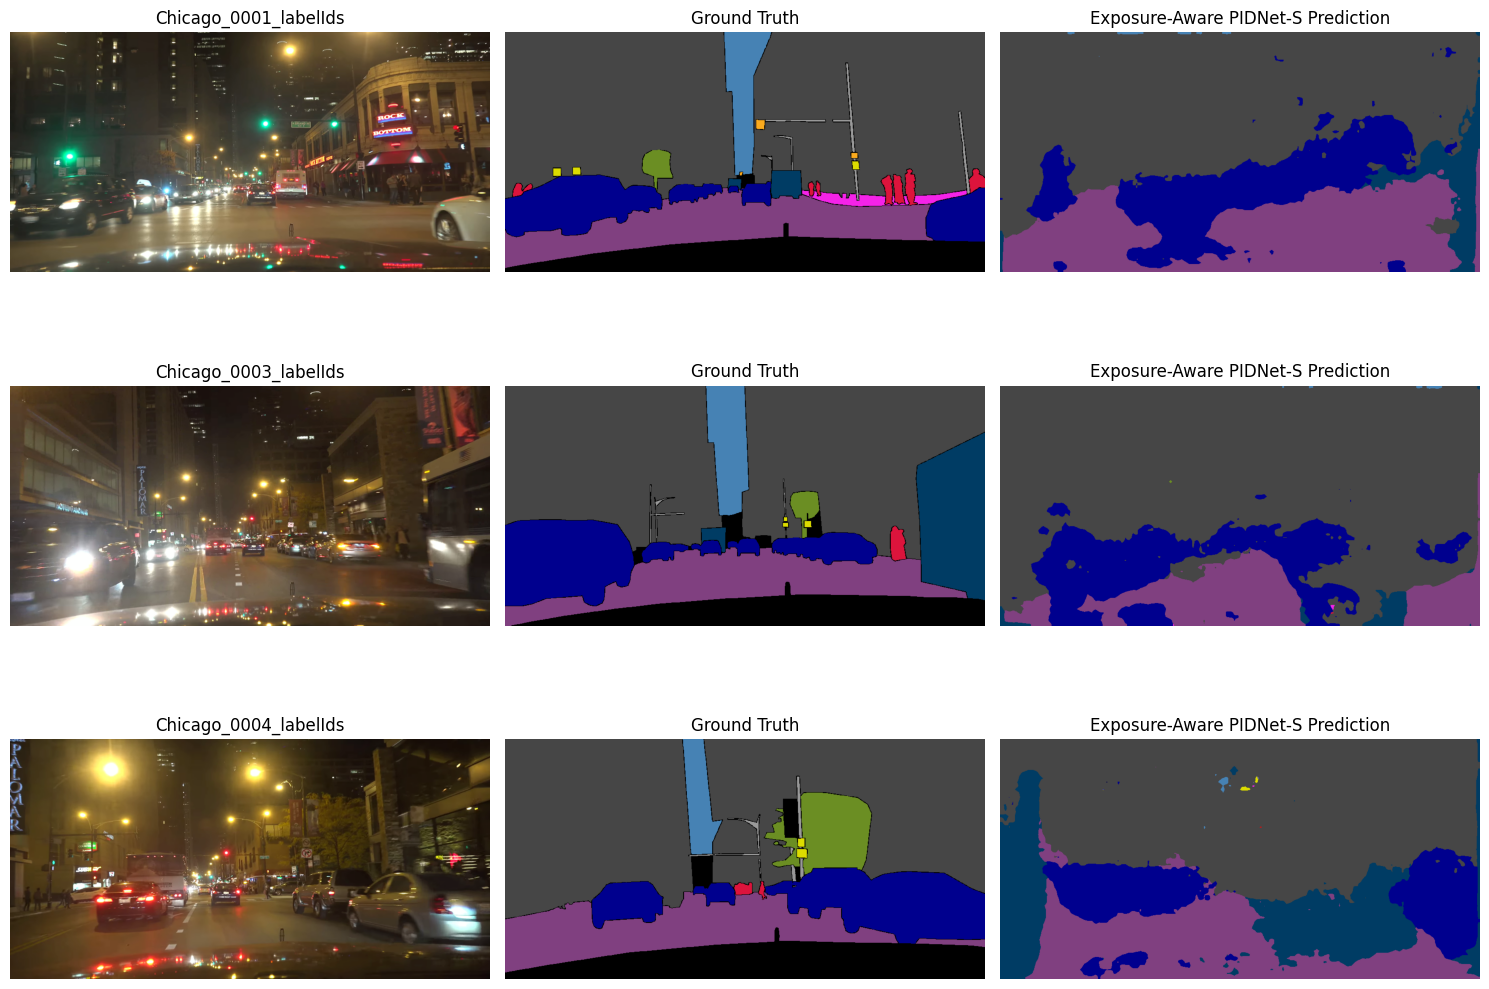

In [6]:
df_cls = pd.DataFrame(summary["Per_Class"])
for col in ["IoU", "Dice", "Sensitivity", "Specificity"]:
    df_cls[f"{col} (%)"] = (df_cls.pop(col) * 100).round(2)
display(df_cls[["Class_ID", "Class_Name", "Pixels_GT", "IoU (%)", "Dice (%)", "Sensitivity (%)", "Specificity (%)"]])

fig, axes = plt.subplots(len(vis_samples), 3, figsize=(15, 3.8 * len(vis_samples)))
for i, (name, rgb, gt, pred) in enumerate(vis_samples):
    axes[i, 0].imshow(rgb); axes[i, 0].set_title(name); axes[i, 0].axis("off")
    axes[i, 1].imshow(colorize_mask(gt)); axes[i, 1].set_title("Ground Truth"); axes[i, 1].axis("off")
    axes[i, 2].imshow(colorize_mask(pred)); axes[i, 2].set_title("Exposure-Aware PIDNet-S Prediction"); axes[i, 2].axis("off")
plt.tight_layout()
plt.show()


## 6. Baseline vs. Exposure-Aware Comparison


In [7]:
hw_type = "GPU" if device.type == "cuda" else "CPU"
display(pd.DataFrame({
    "Metric": ["Method", "Params", "Inference FLOPs (1024x2048)", "Inference Speed", "mIoU (100 Val)", "Pixel Acc", "Inference Overhead"],
    "Baseline PIDNet-S": [
        "Standard PIDNet-S",
        "7.63 M",
        "95.46 G",
        "2.25 FPS (CPU)",
        "6.60%",
        "42.70%",
        "Baseline (0%)"
    ],
    "Ours (Exposure-Aware PIDNet-S)": [
        "Night-Aug + Exposure-OHEM + Aux Illum",
        f"{param_info['total_params_M']:.2f} M",
        f"{flop_profiles[2]['FLOPs_G']:.2f} G",
        f"{speed['FPS']:.2f} FPS ({hw_type})",
        f"{summary['mIoU']*100:.2f}%",
        f"{summary['Pixel_Accuracy']*100:.2f}%",
        "0.0% (Zero Extra FLOPs)"
    ]
}))


,Metric,Baseline PIDNet-S,Ours (Exposure-Aware PIDNet-S)
0,Method,Standard PIDNet-S,Night-Aug + Exposure-OHEM + Aux Illum
1,Params,7.63 M,7.66 M
2,Inference FLOPs (1024x2048),95.46 G,95.46 G
3,Inference Speed,2.25 FPS (CPU),6.87 FPS (CPU)
4,mIoU (100 Val),6.60%,7.34%
5,Pixel Acc,42.70%,44.83%
6,Inference Overhead,Baseline (0%),0.0% (Zero Extra FLOPs)
